# A dynamic hydrotreater, and a reformer over a coking cycle

The refinery units of `difflow_refinery` are steady-state models. `difflow_refinery.dynamic`
gives two of them holdups and runs them in time on difflow's dynamic framework
(`difflow.dynamic.DynamicFlowsheet`):

* **`DynamicHydrotreater`**, built from a solved `Hydrotreater`: a charge heater with a
  furnace lag, the trickle beds as ten cells each (material holdup in gas and liquid,
  catalyst heat capacity), the HP separator's liquid level, and the recycle-gas loop's
  inventory, compressor and makeup. The steady unit's recycle tear becomes ODE states.
* **`DynamicReformerTrain`**, built from a solved `CatalyticReformer`: interstage heaters
  with furnace lags, beds of cells with catalyst heat capacity, and coke on the catalyst
  that can deactivate it -- the semi-regenerative cycle as a trajectory.

Both reuse the steady units' rate laws, phase models and enthalpies, and their rest state
is the steady unit's answer (docs: *Refinery Unit Operations*, "Dynamic operation"). The
holdup sizes are illustrative design values; they set how fast things move, not where they
settle. Every trajectory is differentiable.

This notebook runs three hydrotreater upsets -- a feed-sulfur step, a bed-inlet temperature
step and a ten-minute recycle-compressor trip -- takes a gradient through a trajectory, and
then runs a reformer temperature step and a 120-day coking cycle.

In [1]:
import time
import warnings
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import difflow_refinery as dr
from difflow_refinery.hydrotreating import Hydrotreater, HydrotreaterParams, straight_run_cut
from difflow_refinery.hydrotreating.feed import select_cuts
from difflow_refinery.dynamic import DynamicHydrotreater, DynamicReformerTrain

## The steady hydrotreater

The docs' test diesel: the 230-370 C cut of the docs' sour crude, 50 kg/s, two beds with
15 % quench to the second, 50 bar, LHSV 1, 300 Nm3/m3 treat gas.

In [2]:
assay = dr.Assay([5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95],
                 [t + 273.15 for t in (60, 95, 150, 205, 260, 315, 370, 430, 500, 600, 680)],
                 sg=0.86, light_ends={"propane": 0.5, "n_butane": 1.0, "n_pentane": 1.5},
                 heavy_end=dr.HeavyEnd(), sulfur_wt=1.8, nitrogen_wppm=1500.0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # the docs crude's TBP curve starts above its light ends
    char = dr.characterize(assay, composition=True)
feed = straight_run_cut(char, rate=50.0, cuts=select_cuts(char, 230 + 273.15, 370 + 273.15))
unit = Hydrotreater(char, feed, HydrotreaterParams())
t0 = time.time()
steady = unit.solve(feed)
print(f"steady solve {time.time() - t0:.0f} s")
print(steady.table())

steady solve 27 s
WABT 352.1 C, bed dT 13.8, 7.7 K
product: S 217.8 wppm, N 225.9 wppm, SG 0.8498, aromatics 14.1 vol%, cetane index 58.5
yields (mass): product 98.75 %, wild naphtha 0.39 %, gas 1.211 %
H2: chemical 33.1 Nm3/m3 (196 scf/bbl), makeup 50.3 Nm3/m3, purity 95.0 %
recycle compressor 152.6 kW, purge 35.907 mol/s


## The dynamic hydrotreater

`from_steady` takes the steady unit's layout, kinetics and specs and its solution. Each bed
is ten cells. A cell's gas and liquid residence times come from the bed's holdup volumes
(40 % voids, 12 % of the bed volume liquid) and its design flows; the separator holds five
minutes of liquid, and the loop 30 m3 of gas.

In [3]:
t0 = time.time()
dh = DynamicHydrotreater.from_steady(unit, feed, steady, n_cells=10)
print(f"built in {time.time() - t0:.1f} s: {dh.y0.size} states")
for k, g in enumerate(dh.reactor.beds):
    print(f"bed {k + 1}: {g.W / 1000:.0f} t catalyst; per cell, gas {g.tau_G:.1f} s, liquid {g.tau_L:.1f} s "
          f"(bed: gas {10 * g.tau_G:.0f} s, liquid {10 * g.tau_L / 60:.1f} min)")
print(f"recycle loop inventory turns over in {dh.tau_loop:.0f} s")

built in 8.0 s: 6289 states
bed 1: 67 t catalyst; per cell, gas 3.2 s, liquid 14.9 s (bed: gas 32 s, liquid 2.5 min)
bed 2: 101 t catalyst; per cell, gas 4.2 s, liquid 23.6 s (bed: gas 42 s, liquid 3.9 min)
recycle loop inventory turns over in 77 s


The initial state maps the steady bed profiles onto the cells. Two hours at constant signals
settle it onto the dynamic model's own rest state, which we compare with the steady unit.
The first call compiles the right-hand side once; every scenario after it reuses that
compilation, because the disturbances are integrator arguments, not new functions.

In [4]:
t0 = time.time()
y_rest = dh.settle(2 * 3600.0)
print(f"settled in {time.time() - t0:.0f} s (compile included)")
obs = jax.jit(lambda t, y, a: dh.observe(t, y, a))
o = obs(0.0, y_rest, dh.args())
ref = dh.steady_reference()
rows = [("WABT (C)", o["wabt"] - 273.15, ref["wabt"] - 273.15),
        ("bed 1 outlet (C)", o["bed_T_out"][0] - 273.15, ref["bed_T_out"][0] - 273.15),
        ("bed 2 outlet (C)", o["bed_T_out"][1] - 273.15, ref["bed_T_out"][1] - 273.15),
        ("separator liquid S on cuts (wppm)", o["liquid.S_wppm"], ref["liquid.S_wppm"]),
        ("recycle gas (mol/s)", o["recycle.rate"], ref["recycle.rate"]),
        ("makeup H2 (mol/s)", o["h2.makeup"], ref["h2.makeup"])]
print(f"{'':36s} {'dynamic':>10s} {'steady':>10s}")
for name, a, b in rows:
    print(f"{name:36s} {float(a):10.3f} {float(b):10.3f}")

settled in 40 s (compile included)


                                        dynamic     steady
WABT (C)                                352.134    352.134
bed 1 outlet (C)                        353.786    353.786
bed 2 outlet (C)                        356.647    356.647
separator liquid S on cuts (wppm)       217.428    217.409
recycle gas (mol/s)                     682.239    682.239
makeup H2 (mol/s)                       130.600    130.599


The cells reproduce the steady beds because the reaction in a cell is the steady bed
equations stepped across the cell (one RK4 step per cell here); at rest the holdups pass it
through unchanged. The difference above is that RK4 step's error, about 1e-4 in the liquid
sulfur. The liquid sulfur is the sulfur on the cuts, which the stripper does not change (the
steady unit's product sulfur, on the stripper bottoms with its light ends, differs from it
in the third figure; the stripper and products section is steady here).

In [5]:
print(f"steady product (stripper bottoms) S: {float(steady.outputs['product.S_wppm']):.1f} wppm")

steady product (stripper bottoms) S: 217.8 wppm


## Three upsets

Each scenario is a set of signals with smoothed steps (a 60 s ramp): the feed's sulfur, the
charge heater's setpoint (the bed-1 inlet temperature), and the recycle compressor's
availability. Three hours each, starting at rest.

In [6]:
keys = ["wabt", "liquid.S_wppm", "bed_T_out", "bed_T_in", "cell_T", "recycle.rate", "h2.makeup",
        "vent.rate", "T_heater"]
scenarios = {
    "feed sulfur +20 %": dh.args(steps={"feed_sulfur": [(600.0, 0.2)]}),
    "bed-1 inlet +10 K": dh.args(steps={"T_heater": [(600.0, 10.0)]}),
    "recycle compressor trip, 10 min": dh.args(steps={"compressor": [(600.0, -1.0), (1200.0, 1.0)]}, ramp=30.0),
}
runs = {}
for name, a in scenarios.items():
    t0 = time.time()
    sim = dh.simulate(3 * 3600.0, args=a, y0=y_rest, n_save=181)
    runs[name] = {k: np.asarray(v) for k, v in dh.trajectory(sim, a, keys).items()}
    print(f"{name:34s} {time.time() - t0:5.0f} s, {int(sim.info.n_steps)} steps")

feed sulfur +20 %                     54 s, 1718 steps


bed-1 inlet +10 K                     52 s, 1701 steps


recycle compressor trip, 10 min       54 s, 1734 steps


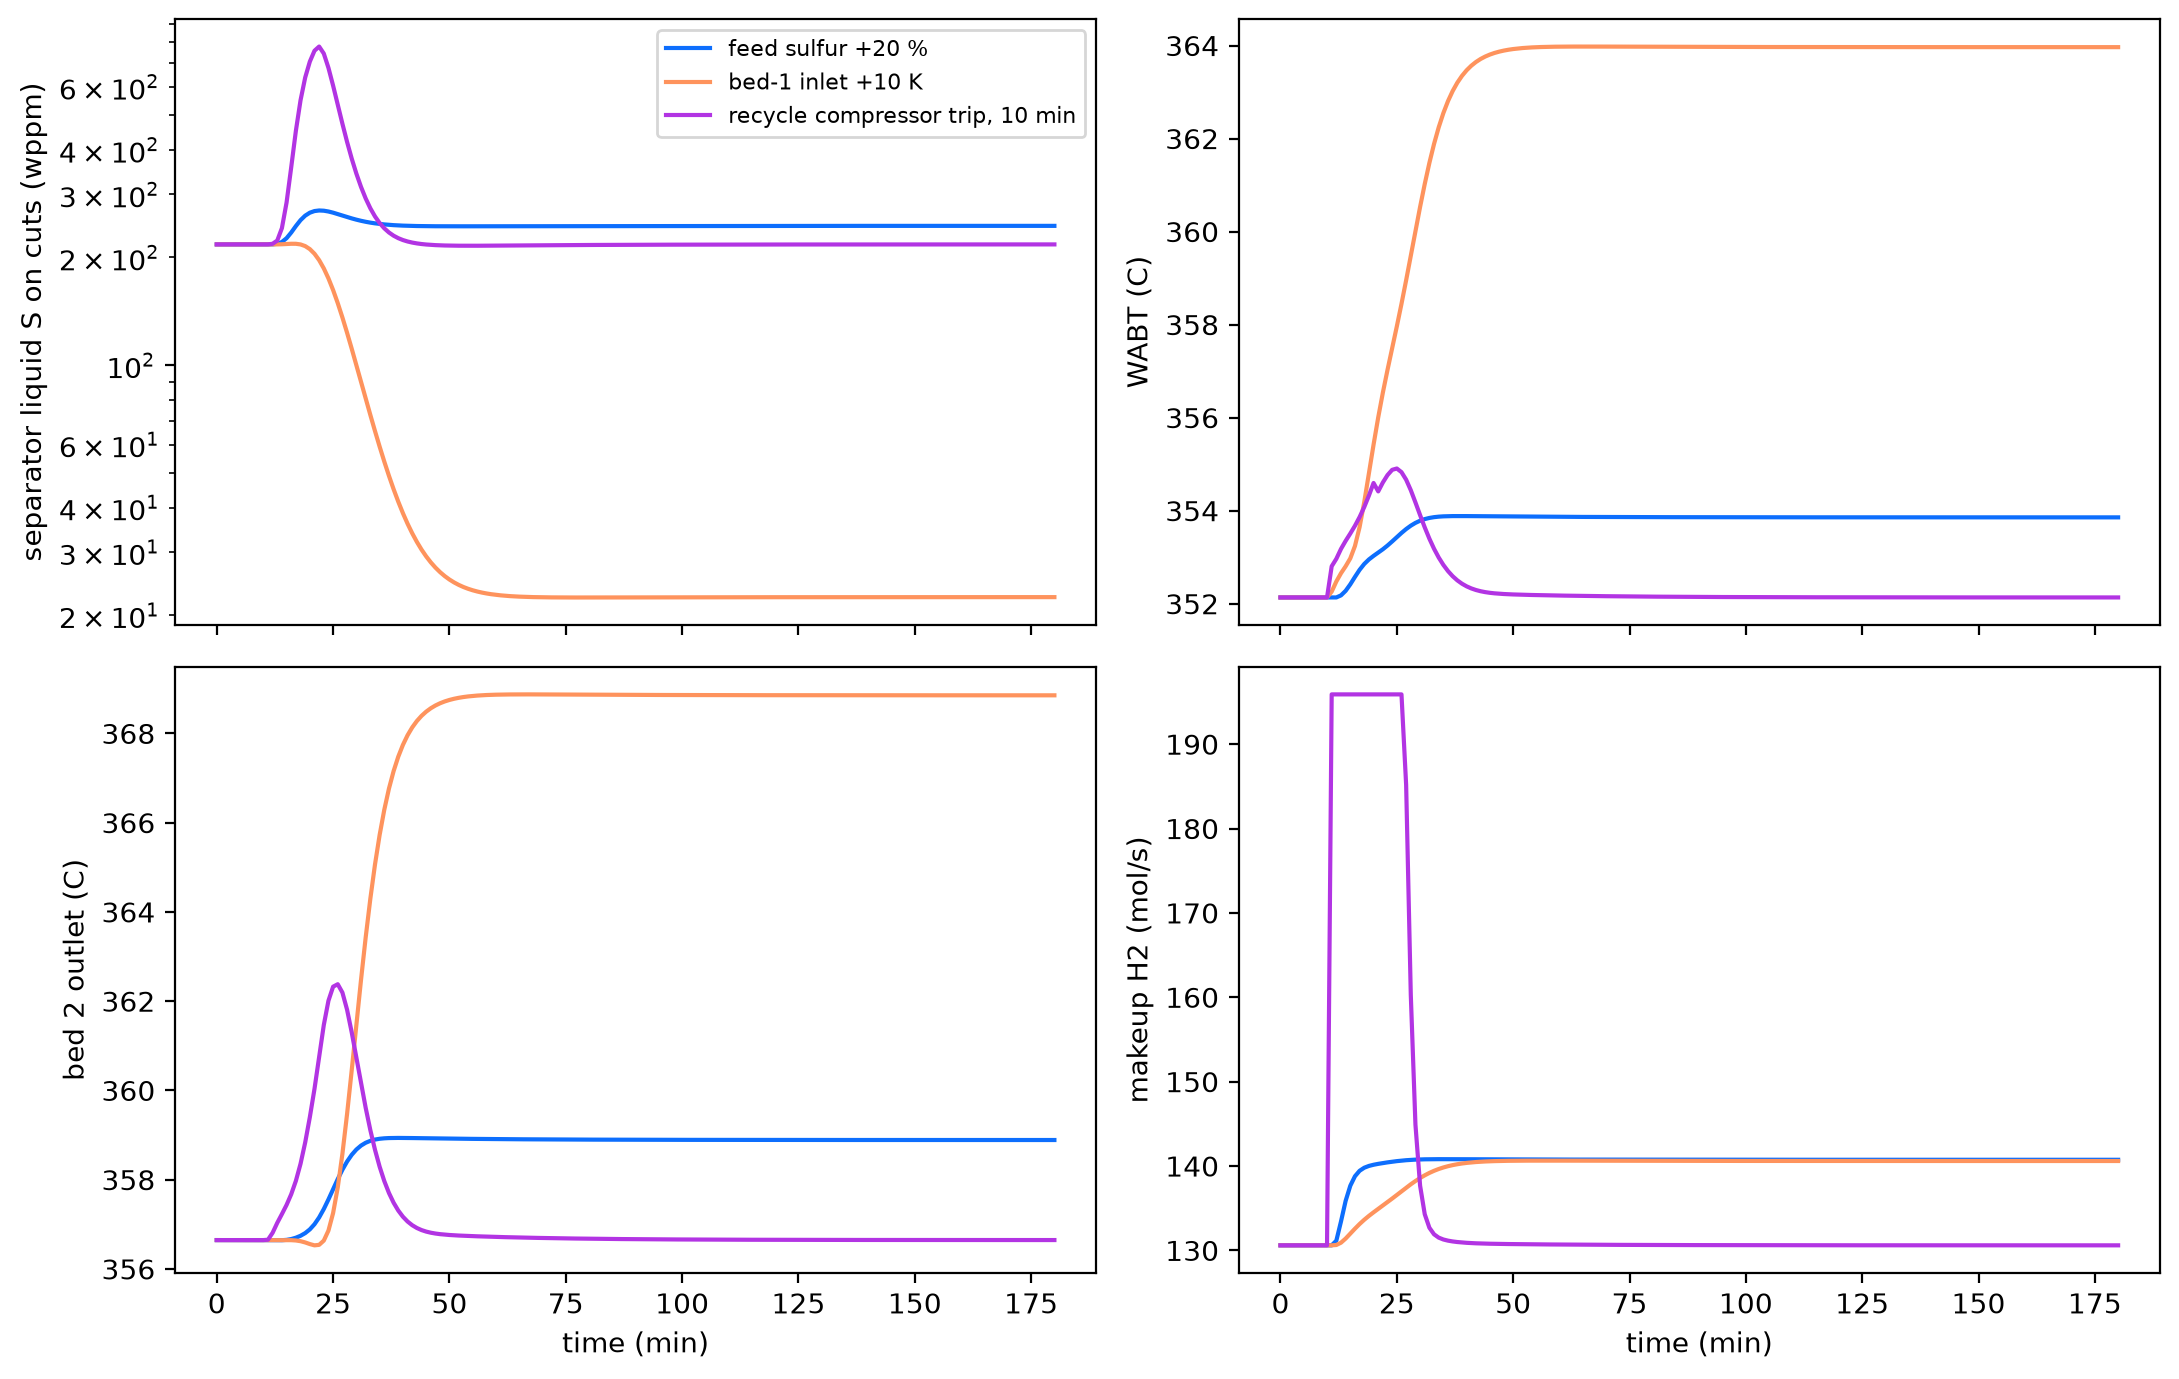

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for name, r in runs.items():
    t = r["t"] / 60
    axes[0, 0].plot(t, r["liquid.S_wppm"], label=name)
    axes[0, 1].plot(t, r["wabt"] - 273.15, label=name)
    axes[1, 0].plot(t, r["bed_T_out"][:, 1] - 273.15, label=name)
    axes[1, 1].plot(t, r["h2.makeup"], label=name)
axes[0, 0].set_ylabel("separator liquid S on cuts (wppm)")
axes[0, 0].set_yscale("log")
axes[0, 1].set_ylabel("WABT (C)")
axes[1, 0].set_ylabel("bed 2 outlet (C)")
axes[1, 1].set_ylabel("makeup H2 (mol/s)")
for ax in axes[1]:
    ax.set_xlabel("time (min)")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()

In [8]:
for name, r in runs.items():
    S = r["liquid.S_wppm"]
    print(f"{name:34s} S {S[0]:6.1f} -> {S[-1]:6.1f} wppm (peak {S.max():6.1f});"
          f" WABT {r['wabt'][0] - 273.15:6.2f} -> {r['wabt'][-1] - 273.15:6.2f} C;"
          f" bed-2 outlet peak {r['bed_T_out'][:, 1].max() - 273.15:6.2f} C")

feed sulfur +20 %                  S  217.4 ->  245.0 wppm (peak  270.4); WABT 352.13 -> 353.86 C; bed-2 outlet peak 358.94 C
bed-1 inlet +10 K                  S  217.4 ->   22.5 wppm (peak  218.3); WABT 352.13 -> 363.96 C; bed-2 outlet peak 368.87 C
recycle compressor trip, 10 min    S  217.4 ->  217.4 wppm (peak  776.5); WABT 352.13 -> 352.13 C; bed-2 outlet peak 362.38 C


**Feed sulfur +20 %.** More sulfur to remove means more heat and more hydrogen: the WABT rises
about 1.7 K and the makeup about 8 %, and the separator liquid settles 13 % richer in sulfur
-- less than 20 %, because the hotter beds remove a larger share. The liquid responds first
(the beds' liquid and the separator hold about eleven minutes of oil) and overshoots, to
270 wppm, before the beds have warmed; the temperatures follow over the beds' thermal
transit times (about 7 and 10 minutes).

**Bed-1 inlet +10 K.** The setpoint step reaches the bed through the furnace lag (5 min), and
then as a thermal wave: the catalyst has to be heated cell by cell, at the speed the oil and
gas carry heat into it. The cell temperatures below show the wave. The liquid sulfur falls
tenfold, which is the default HDS constants' temperature sensitivity (too steep; see the
calibration discussion in the hydrotreater docs), not a dynamic effect: the rest state
after the step is the steady unit's at the new inlet temperature.

**Recycle compressor trip.** With no recycle the treat gas is the makeup alone, raised to
its capacity limit (1.5 times design); the beds lose most of their hydrogen and the quench
gas, the second bed heats, and the separator liquid's sulfur climbs about 3.5-fold. The
loop's gas has nowhere to go and is vented to flare by the loop's pressure controller. After
the restart everything returns to its starting value within the three hours shown.

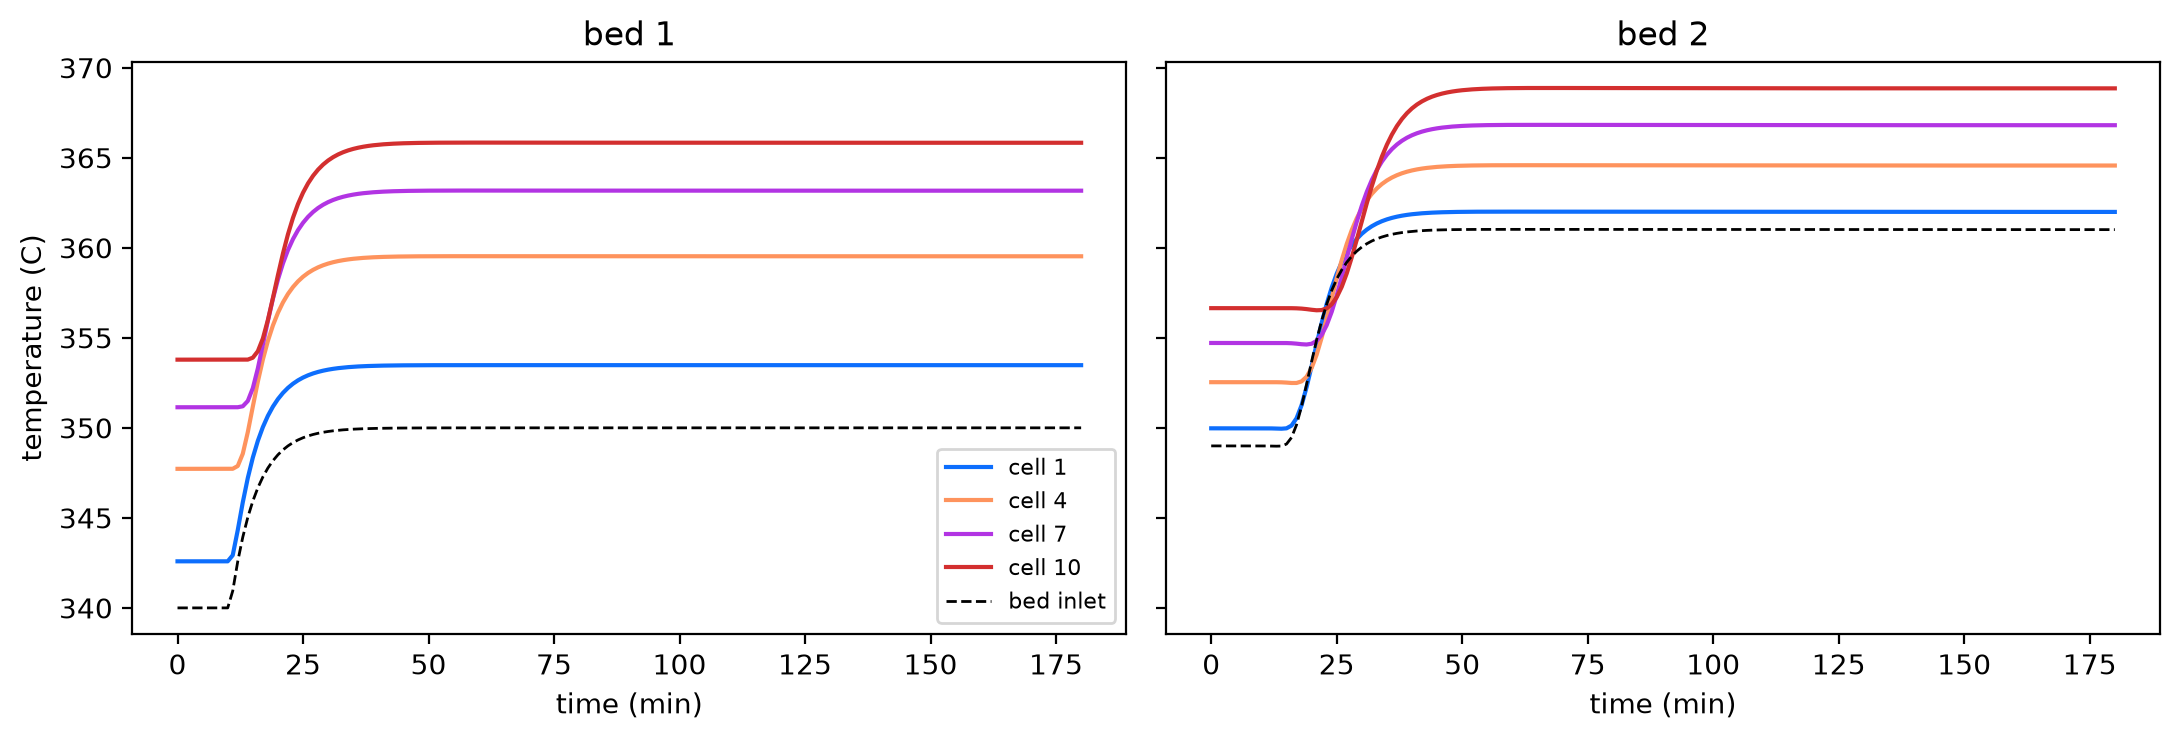

In [9]:
r = runs["bed-1 inlet +10 K"]
t = r["t"] / 60
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for b in range(2):
    for c in range(0, 10, 3):
        axes[b].plot(t, r["cell_T"][:, b, c] - 273.15, label=f"cell {c + 1}")
    axes[b].plot(t, r["bed_T_in"][:, b] - 273.15, "k--", lw=1, label="bed inlet")
    axes[b].set_title(f"bed {b + 1}")
    axes[b].set_xlabel("time (min)")
axes[0].set_ylabel("temperature (C)")
axes[0].legend(fontsize=8)
fig.tight_layout()

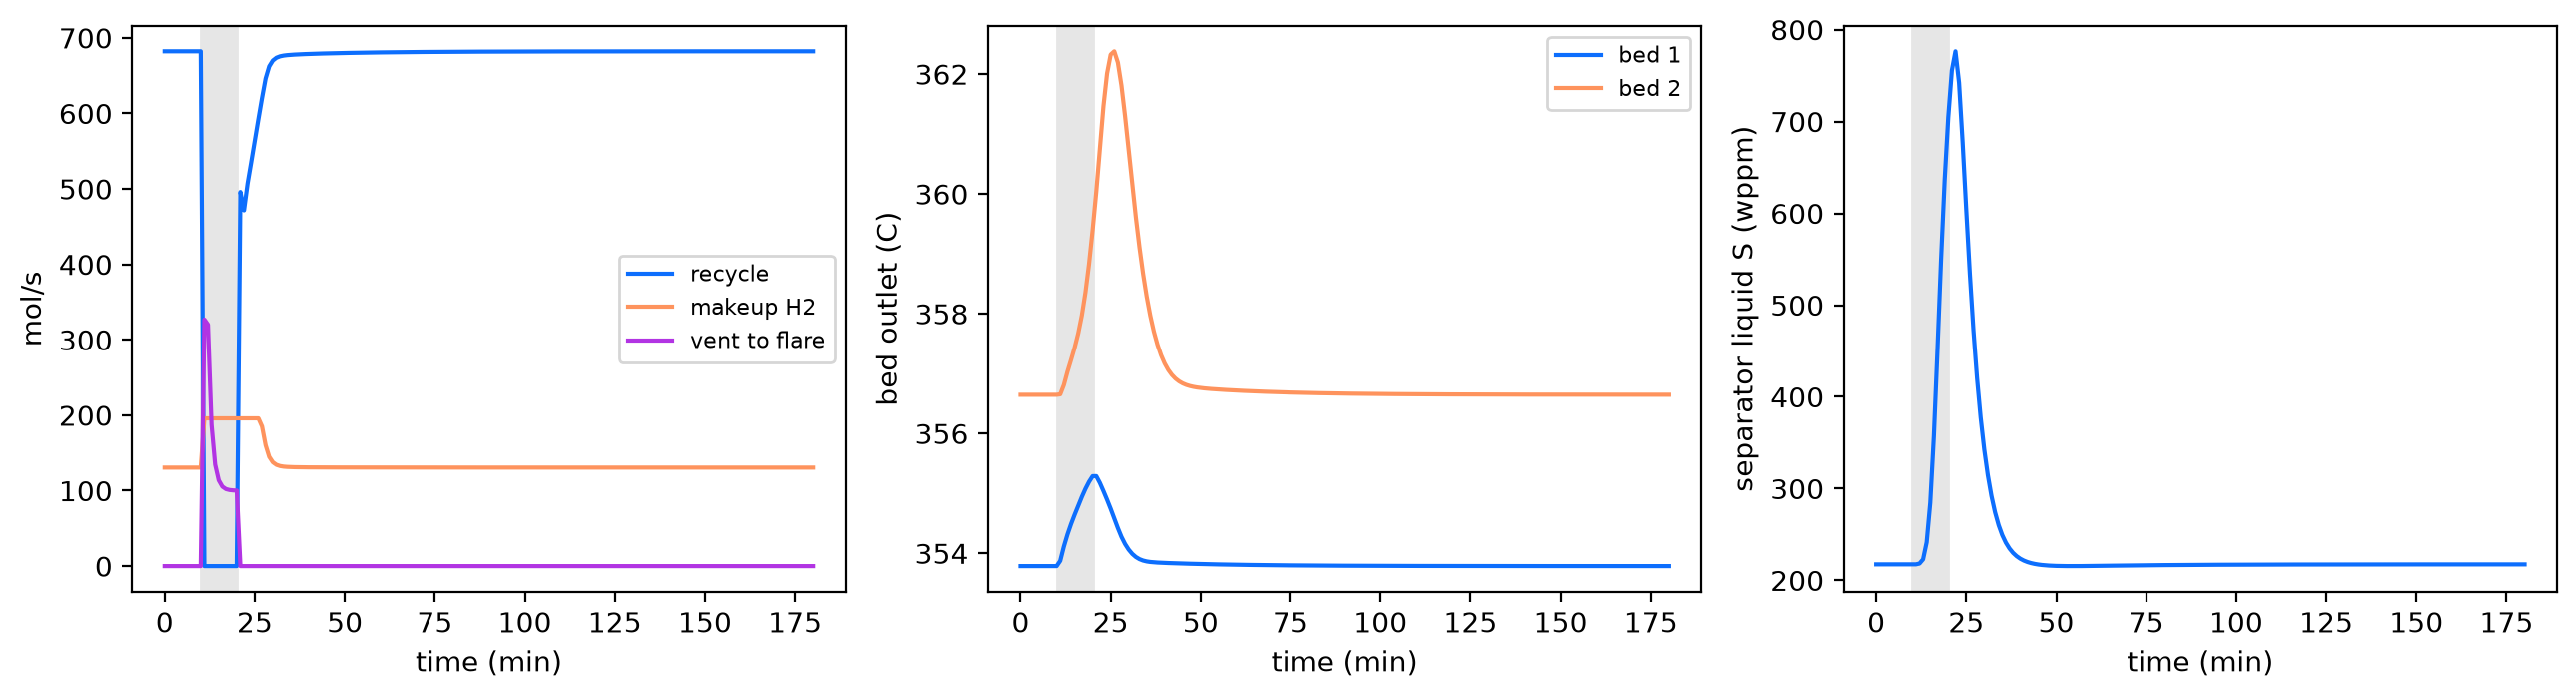

In [10]:
r = runs["recycle compressor trip, 10 min"]
t = r["t"] / 60
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(t, r["recycle.rate"], label="recycle")
axes[0].plot(t, r["h2.makeup"], label="makeup H2")
axes[0].plot(t, r["vent.rate"], label="vent to flare")
axes[0].set_ylabel("mol/s")
axes[0].legend(fontsize=8)
axes[1].plot(t, r["bed_T_out"] - 273.15)
axes[1].set_ylabel("bed outlet (C)")
axes[1].legend(["bed 1", "bed 2"], fontsize=8)
axes[2].plot(t, r["liquid.S_wppm"])
axes[2].set_ylabel("separator liquid S (wppm)")
for ax in axes:
    ax.set_xlabel("time (min)")
    ax.axvspan(10, 20, color="0.9")
fig.tight_layout()

## Balances along a transient

The element balances close at every state of a trajectory, not only at rest: carbon,
hydrogen, sulfur and nitrogen accumulating in the cells, the separator and the loop equal
what enters (oil and makeup) less what leaves (separator liquid and water, purge, acid gas,
vent). Here at the worst moment of the compressor trip:

In [11]:
a = scenarios["recycle compressor trip, 10 min"]
sim = dh.simulate(3 * 3600.0, args=a, y0=y_rest, n_save=181)
i = int(np.argmax(runs["recycle compressor trip, 10 min"]["vent.rate"]))
eb = dh.element_balance(sim.trajectory.t[i], sim.trajectory.y[i], a)
for e, acc, net in zip("CHSN", np.asarray(eb["accumulation"]), np.asarray(eb["in_minus_out"])):
    print(f"{e}: accumulating {acc:12.5f} mol/s, in - out {net:12.5f} mol/s")

C: accumulating    -11.67334 mol/s, in - out    -11.67334 mol/s
H: accumulating   -534.20148 mol/s, in - out   -534.20148 mol/s
S: accumulating      0.86237 mol/s, in - out      0.86237 mol/s
N: accumulating      0.02953 mol/s, in - out      0.02953 mol/s


## A gradient through a trajectory

How much does the separator liquid's sulfur one hour after an inlet-temperature step change
per kelvin of step? Reverse mode through the whole diffrax solve
(`RecursiveCheckpointAdjoint`), against central differences of more simulations. The sulfur
falls about tenfold per 10 K, so a central difference's truncation error is visible at
h = 0.5 K; halving h and extrapolating removes it.

In [12]:
def S_at_1h(dT):
    a = dh.args(steps={"T_heater": [(300.0, dT)]})
    sim = dh.simulate(3600.0, args=a, y0=y_rest, n_save=2)
    return dh.observe(sim.trajectory.t[-1], sim.y_final, a)["liquid.S_wppm"]

t0 = time.time()
g = float(jax.grad(S_at_1h)(jnp.asarray(5.0)))
t_g = time.time() - t0
print(f"reverse mode: {g:.6f} wppm/K ({t_g:.0f} s with its compile)")
fd = {}
for h in (0.5, 0.25):
    fd[h] = (float(S_at_1h(jnp.asarray(5.0 + h))) - float(S_at_1h(jnp.asarray(5.0 - h)))) / (2 * h)
    print(f"central difference, h = {h} K: {fd[h]:.6f} wppm/K (relative difference {abs(g - fd[h]) / abs(g):.1e})")
rich = (4 * fd[0.25] - fd[0.5]) / 3
print(f"Richardson extrapolation of the two: {rich:.6f} wppm/K (relative difference {abs(g - rich) / abs(g):.1e})")

reverse mode: -17.852718 wppm/K (314 s with its compile)


central difference, h = 0.5 K: -17.869290 wppm/K (relative difference 9.3e-04)


central difference, h = 0.25 K: -17.856861 wppm/K (relative difference 2.3e-04)
Richardson extrapolation of the two: -17.852718 wppm/K (relative difference 2.5e-08)


## The reformer: catalyst heat capacity and a coking cycle

The reformer's beds are vapour: the gas crosses a bed in seconds, so it is quasi-steady
here, and the dynamic states are the catalyst temperatures (five cells per bed) and the
coke on the catalyst. A cell's reaction is the steady reformer's own bed integration over
the cell's catalyst. The recycle gas is held at the steady unit's.

steady reformer 38 s; RON 92.50, cycle length 408 days


one hour after a +5 K step at the first reactor's inlet: 134 s


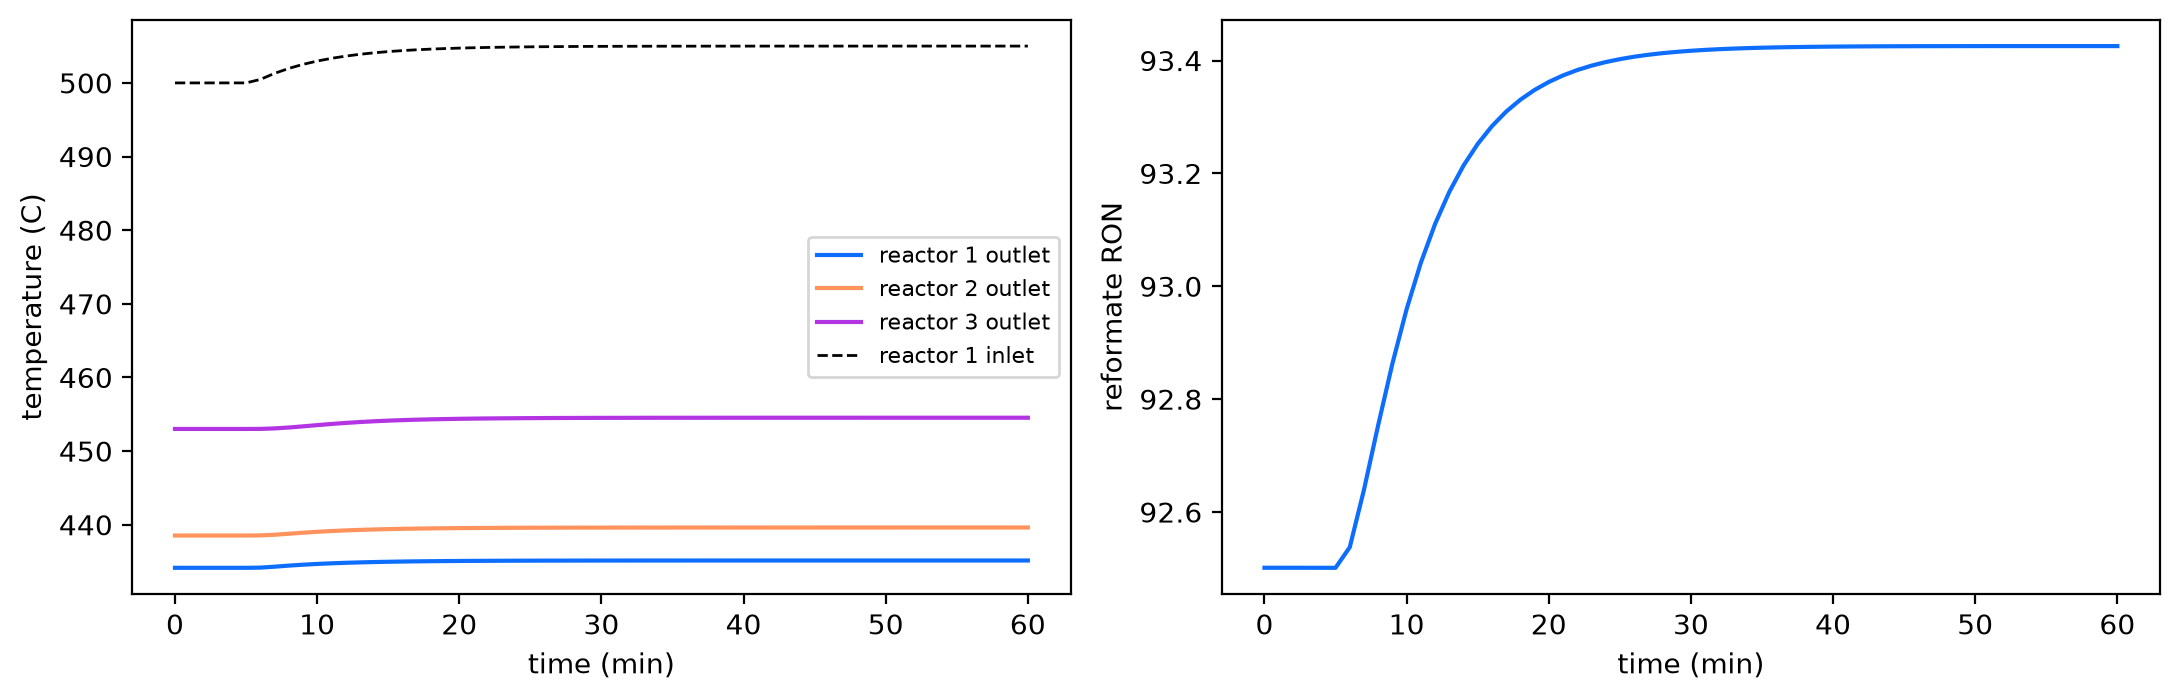

In [13]:
from difflow_refinery.reforming import CatalyticReformer, ReformerParams, lean_naphtha
naphtha = lean_naphtha()
reformer = CatalyticReformer(ReformerParams())
t0 = time.time()
ref_steady = reformer.solve(naphtha)
print(f"steady reformer {time.time() - t0:.0f} s; RON {float(ref_steady.outputs()['reformate.RON']):.2f}, "
      f"cycle length {float(ref_steady.cycle_length_days):.0f} days")
train = DynamicReformerTrain.from_steady(reformer, naphtha, ref_steady, n_cells=5, coke_alpha=10.0)
a = train.args(steps={"T_in1": [(300.0, 5.0)]})
t0 = time.time()
sim = train.simulate(3600.0, args=a, n_save=61)
print(f"one hour after a +5 K step at the first reactor's inlet: {time.time() - t0:.0f} s")
tr = {k: np.asarray(v) for k, v in train.trajectory(sim, a, ["T_in", "T_out", "reformate.RON"]).items()}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k in range(3):
    axes[0].plot(tr["t"] / 60, tr["T_out"][:, k] - 273.15, label=f"reactor {k + 1} outlet")
axes[0].plot(tr["t"] / 60, tr["T_in"][:, 0] - 273.15, "k--", lw=1, label="reactor 1 inlet")
axes[0].set_ylabel("temperature (C)")
axes[0].legend(fontsize=8)
axes[1].plot(tr["t"] / 60, tr["reformate.RON"])
axes[1].set_ylabel("reformate RON")
for ax in axes:
    ax.set_xlabel("time (min)")
fig.tight_layout()

On the coke's time scale the temperatures sit at rest, and `cycle` integrates the coke alone
(the two-time-scale reduction of the same model). With the activity `exp(-10 C)` of the CCR
module (`alpha` illustrative), 120 days at constant inlet temperatures:

120 days in 7 s, 5 steps


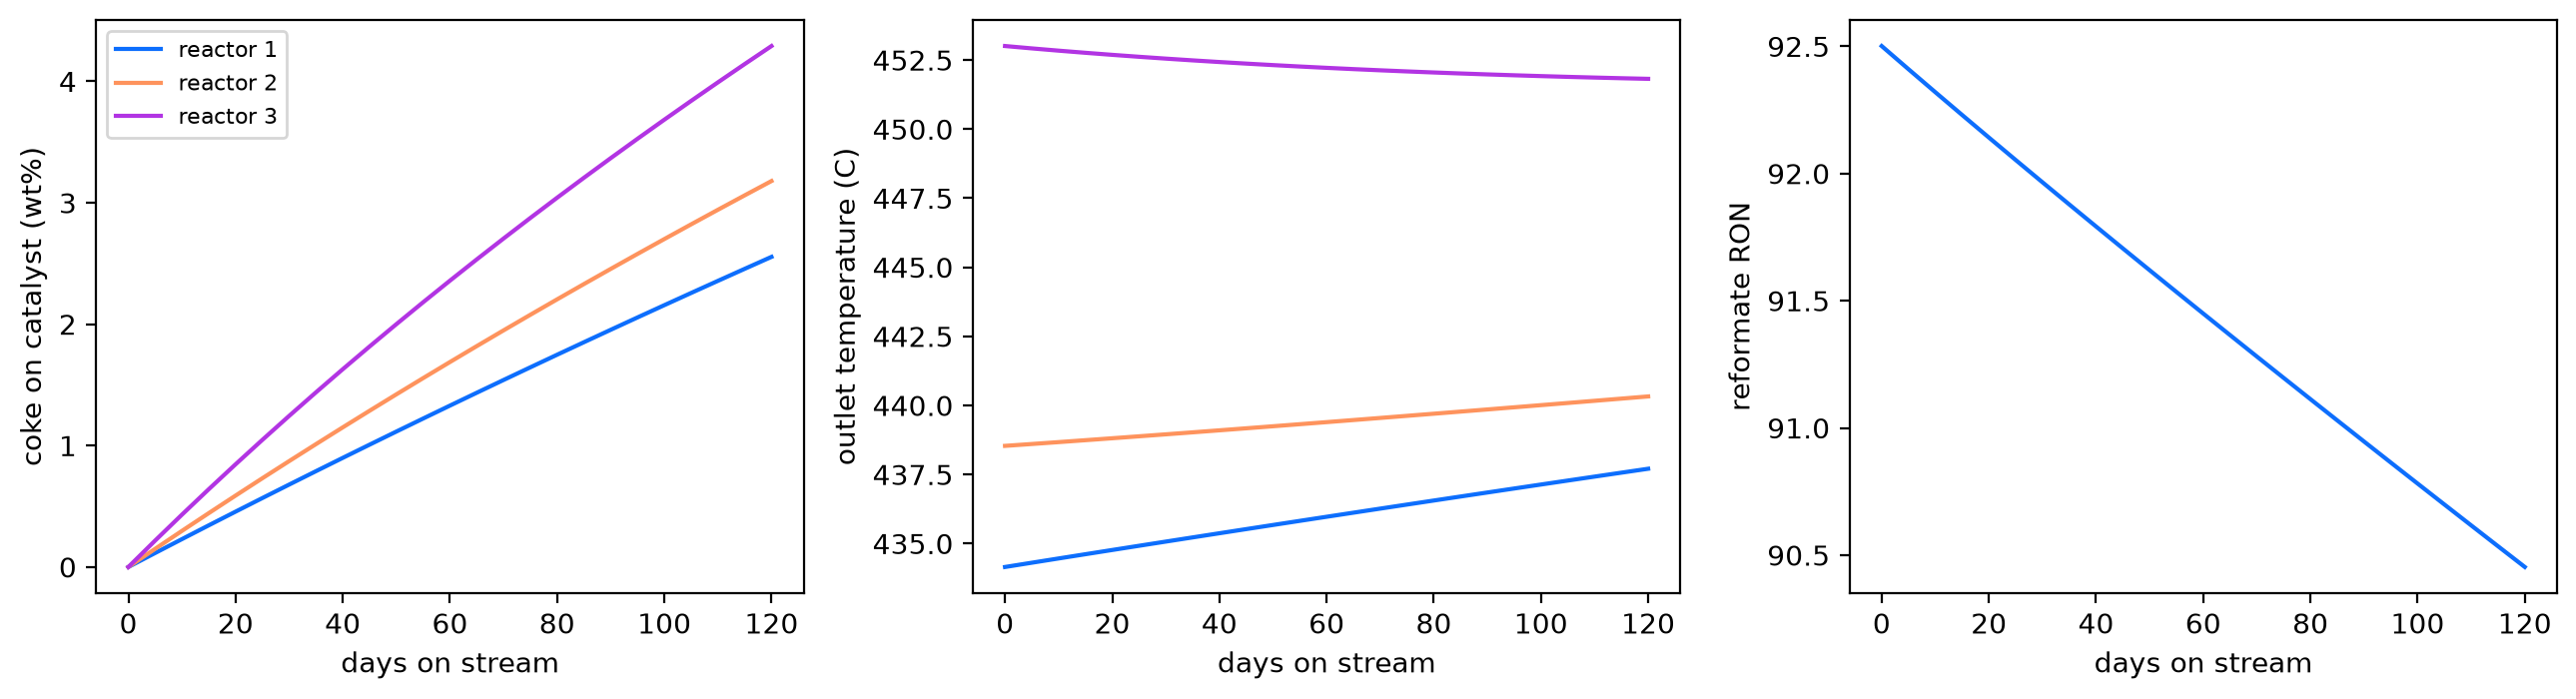

In [14]:
t0 = time.time()
ts, Ccoke, info = train.cycle(120 * 86400.0, n_save=25)
print(f"120 days in {time.time() - t0:.0f} s, {int(info.n_steps)} steps")
co = jax.jit(lambda t, c: train.cycle_observe(t, c))
cyc = [co(t, c) for t, c in zip(ts, Ccoke)]
days = np.asarray(ts) / 86400
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for k in range(3):
    axes[0].plot(days, np.asarray(Ccoke)[:, k].mean(axis=1) * 100, label=f"reactor {k + 1}")
    axes[1].plot(days, [float(c["T_out"][k]) - 273.15 for c in cyc], label=f"reactor {k + 1}")
axes[0].set_ylabel("coke on catalyst (wt%)")
axes[1].set_ylabel("outlet temperature (C)")
axes[2].plot(days, [float(c["reformate.RON"]) for c in cyc])
axes[2].set_ylabel("reformate RON")
for ax in axes:
    ax.set_xlabel("days on stream")
axes[0].legend(fontsize=8)
fig.tight_layout()

As the catalyst cokes it loses activity, the endotherm weakens (the first reactors' outlets
run hotter) and the RON falls -- the reason a semi-regen unit raises its inlet temperatures
through a cycle. An operator's response (raising the WAIT to hold the RON) is one more
signal schedule.

## Summary and limitations

* The dynamic hydrotreater and reformer train run in `difflow.dynamic.DynamicFlowsheet`,
  reuse the steady units' physics, and settle on the steady units' answers; element balances
  close at every state of a transient; gradients through a trajectory match central
  differences. The gate numbers are in the docs ("Dynamic operation") and
  `tests/reference/dynamic_refinery_checks.py`.
* The holdup sizes, the catalyst heat capacity and the time constants (furnace, separator,
  loop) are illustrative design values, and the rate constants are the steady units'
  illustrative ones (the hydrotreater's are too temperature-sensitive by default).
* Not modelled: pressure dynamics (pressures are fixed; flows are not pressure-driven),
  gas-liquid and catalyst-fluid transfer lags, reactor wall heat capacity, controllers
  other than the makeup ratio rule and the loop's vent, the stripper's and stabilizer's
  own dynamics (steady at each time), and the reformer's recycle loop (held).